<a href="https://colab.research.google.com/github/samu975/PPanalisisDatos/blob/main/Rosero_Samuel_Rico_Braian_Analizando_EA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio de extracción de precios de portátiles en Ktronix

Este notebook extrae los portátiles publicados en la categoría **Computadores portátiles** de Ktronix (Colombia) y ubica un artículo destacado frente al resto del mercado de la tienda. La interpretación de los resultados y las conclusiones se presentan en el informe de entrega.

- **Empresa:** Ktronix, tienda colombiana de tecnología.
- **Categoría consultada:** https://www.ktronix.com/computadores-tablets/computadores-portatiles/c/BI_104_KTRON
- **Artículo destacado:** Computador portátil HP 15" fc0287la, AMD Ryzen 7, 8 GB de RAM, SSD de 512 GB (código 199642458734).

Ejecute las celdas en orden con *Entorno de ejecución → Ejecutar todas*. Los valores guardados corresponden a la ejecución indicada en la celda de configuración; una nueva consulta puede mostrar otros precios, descuentos o productos.

## Planteamiento y medidas de éxito

**Problema.** Quien vende o compra un portátil en Colombia necesita saber si un precio es competitivo. La tienda muestra los precios producto por producto, lo que impide comparar el artículo destacado con el resto de la oferta sin copiar los datos a mano.

**Herramienta elegida: Selenium.** La lista de productos de Ktronix se carga con JavaScript después de abrir la página (servicio Algolia). Una solicitud HTTP simple, como la que usan BeautifulSoup o Scrapy, recibe solo tarjetas vacías. La celda *¿Por qué Selenium?* lo muestra con datos.

**Campos por producto:** código, nombre, marca, precio actual, precio anterior, descuento, calificación, número de reseñas y enlace.

**Medidas de éxito** (se calculan al final y se comparan con un umbral fijado de antemano):

| Medida | Umbral |
|---|---|
| Cobertura: productos extraídos frente a los que anuncia la tienda | ≥ 95 % |
| Completitud de nombre y precio actual | 100 % |
| Precios convertidos a número sin error | 100 % |
| Precios coherentes: mayores que cero y no superiores al precio anterior | 100 % |
| Productos repetidos | 0 |
| Artículo destacado encontrado en la categoría | Sí |

## Preparación del entorno

Se instala Selenium (versión fija, para que el resultado no cambie con una actualización) y cuatro bibliotecas que Chrome necesita para funcionar en Colab. Selenium descarga por sí mismo una versión de Chrome compatible, así que no hace falta instalar el navegador aparte. Si la instalación falla, la celda muestra un aviso en lugar de seguir en silencio.

In [ ]:
!pip install -q selenium==4.51.0
!apt-get update -qq > /dev/null 2>&1; apt-get install -y -qq libatk1.0-0t64 libatk-bridge2.0-0t64 libxcomposite1 libatspi2.0-0t64 > /dev/null 2>&1 && echo "Entorno listo." || echo "AVISO: no se pudieron instalar las bibliotecas de Chrome; Selenium puede no arrancar en este entorno."

Entorno listo.


## Configuración de la consulta

Se importan las bibliotecas y se definen la dirección de la categoría, el artículo destacado, el identificador del navegador y la pausa entre solicitudes. La fecha impresa identifica cuándo se ejecutó la consulta.

In [ ]:
import logging
import re
import time
import urllib.robotparser
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.common.exceptions import TimeoutException, WebDriverException
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s", force=True)
log = logging.getLogger("ktronix")

BASE = "https://www.ktronix.com"
URL_CATEGORIA = BASE + "/computadores-tablets/computadores-portatiles/c/BI_104_KTRON"
ID_DESTACADO = "199642458734"  # HP 15" fc0287la, AMD Ryzen 7, 8 GB, SSD 512 GB

USER_AGENT = (
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
    "(KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36"
)
PAUSA_SEGUNDOS = 3      # espera entre cargas de productos, para no saturar el servidor
MAX_CARGAS = 15         # tope de clics en "Mostrar más productos"

# Selectores CSS de la tarjeta de producto
SEL_TARJETA = "li.ais-InfiniteHits-item"
SEL_NOMBRE = "h3.product__item__top__title"
SEL_PRECIO = "span.price"
SEL_PRECIO_ANTES = "p.product__price--discounts__old"
SEL_DESCUENTO = ".product__price--discounts__percentage"
SEL_CALIFICACION = ".product__item__top__rating"
SEL_MOSTRAR_MAS = "button.ais-InfiniteHits-loadMore"
SEL_CONTADOR = ".product__listing__stats"

fecha_consulta = datetime.now(ZoneInfo("America/Bogota"))
print("Consulta ejecutada:", fecha_consulta.strftime("%Y-%m-%d %H:%M"), "(hora de Colombia)")

Consulta ejecutada: 2026-10-24 14:41 (hora de Colombia)


## Consulta del archivo robots.txt

Antes de extraer datos se lee `robots.txt` y se verifica con `urllib.robotparser` si la dirección que se va a consultar está permitida. Ktronix prohíbe, entre otras, la ruta de búsqueda `/search/`; por eso se usa la página de categoría y no el buscador. Revisar este archivo no reemplaza la lectura de los términos de uso del sitio.

In [ ]:
respuesta_robots = requests.get(BASE + "/robots.txt", headers={"User-Agent": USER_AGENT}, timeout=20)
print("Estado HTTP:", respuesta_robots.status_code)
reglas = [l.strip() for l in respuesta_robots.text.splitlines() if l.strip().startswith(("User-agent", "Allow", "Disallow"))]
print("\n".join(reglas[:8]))

robots = urllib.robotparser.RobotFileParser()
robots.parse(respuesta_robots.text.splitlines())
print()
print("¿Categoría permitida?          ", robots.can_fetch("*", URL_CATEGORIA))
print("¿Buscador (/search/) permitido?", robots.can_fetch("*", BASE + "/search/?text=portatil"))

Estado HTTP: 200
User-agent: *
Allow: /
Disallow: *?q=
Disallow: /cart$
Disallow: /checkout
Disallow: /my-account
Disallow: /search/
User-agent: AdsBot-Google

¿Categoría permitida?           True
¿Buscador (/search/) permitido? False


## ¿Por qué Selenium? Prueba con BeautifulSoup

Se pide la misma página con `requests` y se analiza con BeautifulSoup. Si la lista dependiera solo del HTML, aparecerían los nombres de los productos. En cambio, las tarjetas llegan vacías, marcadas como `skeleton` (marcador de carga): el contenido lo agrega JavaScript en el navegador. Selenium controla un navegador real, ejecuta ese JavaScript y por eso sí puede leer los productos.

In [ ]:
html = requests.get(URL_CATEGORIA, headers={"User-Agent": USER_AGENT}, timeout=20).text
sopa = BeautifulSoup(html, "html.parser")
tarjetas_html = sopa.select(".product__item")

print("Tarjetas en el HTML recibido:      ", len(tarjetas_html))
print("Tarjetas vacías (skeleton):        ", len(sopa.select(".product__item.skeleton")))
print("Tarjetas con nombre de producto:   ", len(sopa.select(SEL_NOMBRE)))
print("Ejemplo de tarjeta:", tarjetas_html[0] if tarjetas_html else None)

Tarjetas en el HTML recibido:       25
Tarjetas vacías (skeleton):         25
Tarjetas con nombre de producto:    0
Ejemplo de tarjeta: <div class="product__item product__item--loading skeleton"></div>


## Extracción con Selenium

1. Se abre Chrome sin ventana (*headless*) y se carga la categoría.
2. Se espera de forma explícita (`WebDriverWait`) a que aparezcan los nombres de los productos.
3. Se pulsa **Mostrar más productos** hasta que la tienda no tenga más, con una pausa de `PAUSA_SEGUNDOS` entre clics.
4. Se lee cada tarjeta. Se usa `textContent` en lugar de `.text` porque algunos elementos están ocultos y `.text` devuelve vacío.

In [ ]:
def crear_navegador():
    opciones = webdriver.ChromeOptions()
    for argumento in ["--headless=new", "--no-sandbox", "--disable-dev-shm-usage",
                      "--window-size=1366,900", "--user-agent=" + USER_AGENT]:
        opciones.add_argument(argumento)
    return webdriver.Chrome(options=opciones)


def texto(elemento, selector):
    encontrados = elemento.find_elements(By.CSS_SELECTOR, selector)
    if not encontrados:
        return None
    return re.sub(r"\s+", " ", encontrados[0].get_attribute("textContent")).strip() or None


def cargar_todos(navegador):
    for carga in range(MAX_CARGAS):
        botones = navegador.find_elements(By.CSS_SELECTOR, SEL_MOSTRAR_MAS)
        if not botones or "disabled" in (botones[0].get_attribute("class") or ""):
            break
        antes = len(navegador.find_elements(By.CSS_SELECTOR, SEL_TARJETA))
        navegador.execute_script("arguments[0].scrollIntoView({block: 'center'}); arguments[0].click();", botones[0])
        try:
            WebDriverWait(navegador, 20).until(lambda n: len(n.find_elements(By.CSS_SELECTOR, SEL_TARJETA)) > antes)
        except TimeoutException:
            log.warning("La carga %d no agregó productos; se detiene la paginación.", carga + 1)
            break
        time.sleep(PAUSA_SEGUNDOS)


def leer_tarjeta(tarjeta):
    titulo = tarjeta.find_elements(By.CSS_SELECTOR, SEL_NOMBRE)
    return {
        "codigo": titulo[0].get_attribute("data-id") if titulo else None,
        "nombre": texto(tarjeta, SEL_NOMBRE),
        "precio_texto": texto(tarjeta, SEL_PRECIO),
        "precio_antes_texto": texto(tarjeta, SEL_PRECIO_ANTES),
        "descuento_texto": texto(tarjeta, SEL_DESCUENTO),
        "calificacion_texto": texto(tarjeta, SEL_CALIFICACION),
        "enlace": BASE + titulo[0].get_attribute("data-url") if titulo and titulo[0].get_attribute("data-url") else None,
    }


inicio = time.time()
navegador = None
productos, contador = [], None
try:
    navegador = crear_navegador()
    navegador.get(URL_CATEGORIA)
    WebDriverWait(navegador, 25).until(lambda n: n.find_elements(By.CSS_SELECTOR, SEL_TARJETA + " " + SEL_NOMBRE))
    cargar_todos(navegador)
    productos = [leer_tarjeta(t) for t in navegador.find_elements(By.CSS_SELECTOR, SEL_TARJETA)]
    contador = texto(navegador, SEL_CONTADOR)
except TimeoutException:
    log.error("La página no mostró productos a tiempo.")
except WebDriverException as error:
    log.error("Falló el navegador: %s", error.msg)
finally:
    if navegador:
        navegador.quit()

crudo = pd.DataFrame(productos)
print(f"Productos leídos: {len(crudo)} en {time.time() - inicio:.0f} s")
print("Contador de la tienda:", contador)
crudo.head()

Productos leídos: 171 en 92 s
Contador de la tienda: Has visto 171 de 171 productos


,codigo,nombre,precio_texto,precio_antes_texto,descuento_texto,calificacion_texto,enlace
0,4711636571517,"Computador Portátil ASUS ExpertBook B1 14"" Pul...",$2.599.050,$4.099.000,-36%,5.0 (1),https://www.ktronix.com/computador-portatil-as...
1,199642458734,"Computador Portátil HP 15"" Pulgadas fc0287la -...",$2.099.070,$4.149.000,-49%,4.9 (17),https://www.ktronix.com/computador-portatil-hp...
2,4711474145772,"Computador Portátil ACER ASPIRE VERO 14"" Pulga...",$2.618.030,$5.599.000,-53%,4.5 (2),https://www.ktronix.com/computador-portatil-ac...
3,4711636625630,Computador Portátil ASUS Vivobook 15.6” Pulgad...,$2.199.050,$3.999.050,-45%,None,https://www.ktronix.com/computador-portatil-as...
4,198990787213,"Computador Portátil HP 15"" Pulgadas fd0131la T...",$1.899.070,$3.399.000,-44%,5.0 (2),https://www.ktronix.com/computador-portatil-hp...


## Limpieza y transformación

Los valores llegan como texto (`"$2.099.070"`, `"-49%"`, `"4.9 (17)"`). Se convierten a números, se obtiene la marca a partir del nombre (los MacBook no mencionan a Apple, por eso se reconocen por la línea) y se eliminan los productos repetidos. Cuando un producto no tiene descuento, la tienda no muestra precio anterior: en ese caso se usa el precio actual y un descuento de 0 %.

In [ ]:
def a_pesos(valor):
    digitos = re.sub(r"\D", "", valor or "")
    return int(digitos) if digitos else None


def a_porcentaje(valor):
    hallado = re.search(r"(\d+)\s*%", valor or "")
    return int(hallado.group(1)) if hallado else 0


MARCAS = ["LENOVO", "ASUS", "HP", "ACER", "MSI", "DELL", "SAMSUNG", "HUAWEI", "GIGABYTE", "MICROSOFT"]
ALIAS = {"MACBOOK": "APPLE", "OMNIBOOK": "HP"}  # líneas cuyo nombre no menciona la marca


def marca_desde_nombre(nombre):
    palabras = re.findall(r"[A-Za-z]+", (nombre or "").upper())
    for palabra in palabras:
        if palabra in MARCAS:
            return palabra
        if palabra in ALIAS:
            return ALIAS[palabra]
    return "OTRA"


datos = crudo.copy()
datos["marca"] = datos["nombre"].map(marca_desde_nombre)
datos["precio"] = datos["precio_texto"].map(a_pesos)
datos["precio_antes"] = datos["precio_antes_texto"].map(a_pesos).fillna(datos["precio"]).astype("Int64")
datos["descuento_pct"] = datos["descuento_texto"].map(a_porcentaje)
datos.loc[datos["precio_antes_texto"].isna(), "descuento_pct"] = 0
datos["calificacion"] = pd.to_numeric(datos["calificacion_texto"].str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
datos["resenas"] = pd.to_numeric(datos["calificacion_texto"].str.extract(r"\((\d+)\)")[0], errors="coerce").fillna(0).astype(int)

repetido = datos["codigo"].notna() & datos.duplicated("codigo")  # una tarjeta sin código no cuenta como repetida
repetidos = int(repetido.sum())
datos = datos[~repetido].reset_index(drop=True)
datos["fecha_consulta"] = fecha_consulta.strftime("%Y-%m-%d")

columnas = ["codigo", "marca", "nombre", "precio", "precio_antes", "descuento_pct",
            "calificacion", "resenas", "enlace", "fecha_consulta"]
datos = datos[columnas]
print("Repetidos eliminados:", repetidos)
datos.info()

Repetidos eliminados: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   codigo          171 non-null    object 
 1   marca           171 non-null    object 
 2   nombre          171 non-null    object 
 3   precio          171 non-null    int64  
 4   precio_antes    171 non-null    Int64  
 5   descuento_pct   171 non-null    int64  
 6   calificacion    61 non-null     float64
 7   resenas         171 non-null    int64  
 8   enlace          171 non-null    object 
 9   fecha_consulta  171 non-null    object 
dtypes: Int64(1), float64(1), int64(3), object(5)
memory usage: 13.7+ KB


## Almacenamiento en CSV

Se guarda una copia con la fecha en el nombre. Al repetir la consulta otro día se obtiene un archivo nuevo, lo que permite comparar cómo cambian los precios en el tiempo (base para las siguientes evidencias). En Colab, el archivo queda en el panel *Archivos*.

In [ ]:
archivo_csv = f"ktronix_portatiles_{fecha_consulta:%Y-%m-%d}.csv"
datos.to_csv(archivo_csv, index=False, encoding="utf-8")
print("Archivo guardado:", archivo_csv, "|", len(datos), "filas")

Archivo guardado: ktronix_portatiles_2026-10-24.csv | 171 filas


## Cálculo de las métricas de éxito

Se comparan los resultados de esta ejecución con los umbrales definidos al inicio.

In [ ]:
anunciados = int(re.findall(r"\d+", contador)[-1]) if contador else None
cobertura = len(datos) / anunciados if anunciados else 0
completitud = datos[["nombre", "precio"]].notna().all(axis=1).mean() if len(datos) else 0
precios_validos = crudo["precio_texto"].map(a_pesos).notna().mean() if len(crudo) else 0
destacado_encontrado = ID_DESTACADO in set(datos["codigo"])
precios_coherentes = ((datos["precio"] > 0) & (datos["precio"] <= datos["precio_antes"])).mean() if len(datos) else 0

metricas = pd.DataFrame([
    ["Cobertura frente a lo anunciado", f"{len(datos)}/{anunciados} = {cobertura:.0%}", "≥ 95 %", cobertura >= 0.95],
    ["Completitud de nombre y precio", f"{completitud:.0%}", "100 %", completitud == 1],
    ["Precios convertidos a número", f"{precios_validos:.0%}", "100 %", precios_validos == 1],
    ["Precios coherentes (> 0 y ≤ precio anterior)", f"{precios_coherentes:.0%}", "100 %", precios_coherentes == 1],
    ["Productos repetidos", repetidos, "0", repetidos == 0],
    ["Artículo destacado encontrado", "Sí" if destacado_encontrado else "No", "Sí", destacado_encontrado],
], columns=["Medida", "Resultado", "Umbral", "Cumple"])
metricas["Cumple"] = metricas["Cumple"].map({True: "Sí", False: "No"})
metricas

,Medida,Resultado,Umbral,Cumple
0,Cobertura frente a lo anunciado,171/171 = 100%,≥ 95 %,Sí
1,Completitud de nombre y precio,100%,100 %,Sí
2,Precios convertidos a número,100%,100 %,Sí
3,Precios coherentes (> 0 y ≤ precio anterior),100%,100 %,Sí
4,Productos repetidos,0,0,Sí
5,Artículo destacado encontrado,Sí,Sí,Sí


## El artículo destacado frente a la categoría

Se ubica el precio del artículo destacado frente a todos los portátiles de la categoría y frente a los de su misma marca. El percentil indica qué proporción de los portátiles cuesta menos que el artículo.

In [ ]:
if destacado_encontrado:
    destacado = datos.loc[datos["codigo"] == ID_DESTACADO].iloc[0]
else:
    destacado = datos.sort_values("resenas", ascending=False).iloc[0]
    log.warning("El artículo %s no apareció; se usa el más reseñado: %s", ID_DESTACADO, destacado["codigo"])

misma_marca = datos[datos["marca"] == destacado["marca"]]
percentil = (datos["precio"] < destacado["precio"]).mean()

print(destacado["nombre"])
print(f"  Precio actual:   ${destacado['precio']:,.0f}".replace(",", "."))
print(f"  Precio anterior: ${destacado['precio_antes']:,.0f}".replace(",", ".") + f"  (descuento {destacado['descuento_pct']} %)")
print(f"  Calificación:    {destacado['calificacion']} con {destacado['resenas']} reseñas")
print()
resumen = pd.DataFrame({
    "Grupo": ["Toda la categoría", f"Marca {destacado['marca']}"],
    "Productos": [len(datos), len(misma_marca)],
    "Precio mínimo": [datos["precio"].min(), misma_marca["precio"].min()],
    "Mediana": [datos["precio"].median(), misma_marca["precio"].median()],
    "Precio máximo": [datos["precio"].max(), misma_marca["precio"].max()],
    "Descuento promedio (%)": [round(datos["descuento_pct"].mean(), 1), round(misma_marca["descuento_pct"].mean(), 1)],
})
for columna in ["Precio mínimo", "Mediana", "Precio máximo"]:
    resumen[columna] = resumen[columna].map(lambda v: f"${v:,.0f}".replace(",", "."))
print(f"El {percentil:.0%} de los portátiles de la categoría cuesta menos que el artículo destacado.")
resumen

Computador Portátil HP 15" Pulgadas fc0287la - AMD Ryzen 7 - RAM 8GB - Disco SSD 512GB - Plateado
  Precio actual:   $2.099.070
  Precio anterior: $4.149.000  (descuento 49 %)
  Calificación:    4.9 con 17 reseñas

El 13% de los portátiles de la categoría cuesta menos que el artículo destacado.


,Grupo,Productos,Precio mínimo,Mediana,Precio máximo,Descuento promedio (%)
0,Toda la categoría,171,$1.499.070,$4.999.050,$31.999.050,28.1
1,Marca HP,29,$1.499.070,$4.499.070,$16.499.070,35.7


## Gráficos

A la izquierda, cuántos portátiles publica Ktronix por marca. A la derecha, la distribución de precios de la categoría; la línea marca el precio del artículo destacado. El histograma muestra los equipos de hasta 15 millones de pesos para que la mayoría de la oferta se vea con detalle; el rótulo indica cuántos quedan fuera.

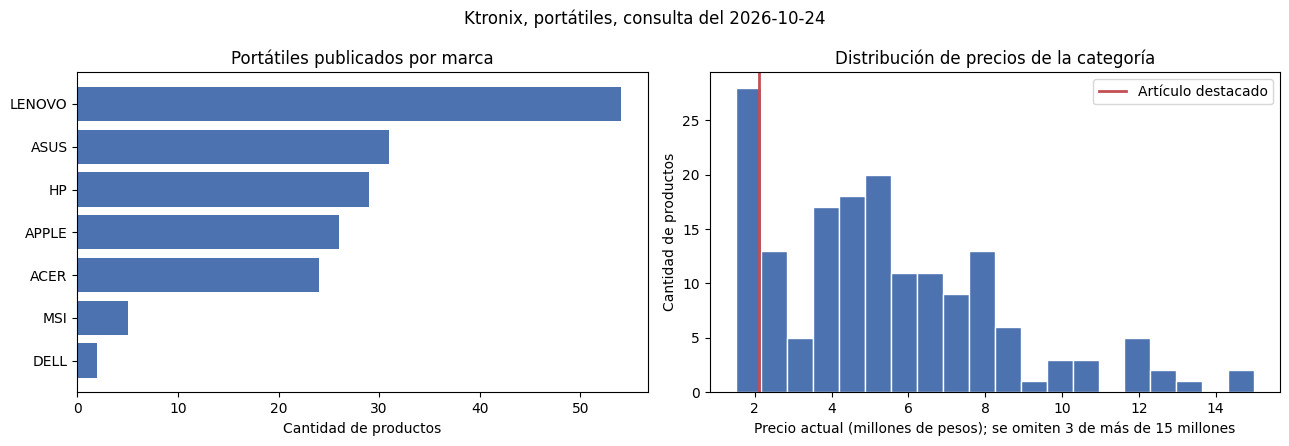

In [ ]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.5))

conteo = datos["marca"].value_counts().sort_values()
izq.barh(conteo.index, conteo.values, color="#4C72B0")
izq.set_title("Portátiles publicados por marca")
izq.set_xlabel("Cantidad de productos")

LIMITE_GRAFICO = 15_000_000  # unos pocos equipos muy caros aplastarían el histograma
visibles = datos[datos["precio"] <= LIMITE_GRAFICO]
omitidos = len(datos) - len(visibles)
der.hist(visibles["precio"] / 1e6, bins=20, color="#4C72B0", edgecolor="white")
der.axvline(destacado["precio"] / 1e6, color="#C44E52", linewidth=2, label="Artículo destacado")
der.set_title("Distribución de precios de la categoría")
der.set_xlabel(f"Precio actual (millones de pesos); se omiten {omitidos} de más de 15 millones")
der.set_ylabel("Cantidad de productos")
der.legend()

fig.suptitle(f"Ktronix, portátiles, consulta del {fecha_consulta:%Y-%m-%d}")
fig.tight_layout()
plt.show()

## Conclusiones (ejecución del 24 de octubre de 2026)

- **La herramienta fue la adecuada.** La lista de productos de Ktronix se carga con JavaScript: BeautifulSoup recibió 25 tarjetas vacías y ningún nombre. Selenium, al usar un navegador real, obtuvo los 171 portátiles que anuncia la tienda.
- **Las seis medidas de éxito se cumplieron:** cobertura del 100 %, nombre y precio en todos los productos, todos los precios convertidos a número y coherentes, ningún repetido y el artículo destacado encontrado.
- **El artículo destacado tiene un precio muy competitivo.** El HP 15" fc0287la se vende a \$2.099.070, con 49 % de descuento. Solo el 13 % de los portátiles de la categoría cuesta menos, y su precio está por debajo de la mediana de la categoría (\$4.999.050) y de la de su marca (\$4.499.070). Tiene una calificación de 4,9 sobre 5, con 17 reseñas.
- **La tienda compite con descuentos altos:** el descuento promedio de la categoría es de 28,1 %, y el de HP, de 35,7 %; el 49 % del artículo destacado supera a ambos. Lenovo es la marca con más portátiles publicados.

**Limitaciones.** Los datos corresponden a un solo día. El total de referencia (171) lo informa la propia tienda. La mayoría de los productos no tiene calificaciones, por lo que esa columna describe solo una parte de la oferta. La categoría incluye al menos un equipo que no es portátil (un All in One). Los selectores dependen del diseño actual del sitio y pueden dejar de funcionar si este cambia.

**Siguiente paso.** Repetir la consulta de forma periódica y versionar los CSV con Git para seguir la evolución de los precios, como base de la siguiente evidencia.